In [16]:
import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from typing import Optional, Tuple

In [50]:
def data_split(data: pd.DataFrame, test_cutoff_date: str = '2023-12-31'):
    # 1. Daten auf Stichtag begrenzen (Kein Blick in die Zukunft für den VAE!)
    df_historical = data[data['Date'] <= test_cutoff_date].copy()
    # 2. Unique Firmen (Entities) splitten
    unique_entities = df_historical['EntityCode'].unique()
    train_entities, temp_entities = train_test_split(unique_entities, train_size=0.70, random_state=42, shuffle=True)
    val_entities, test_entities = train_test_split(temp_entities, test_size=0.50, random_state=42, shuffle=True)
    # 3. Train & Val (Panel-Daten: alle historischen Bilanzen <= Cutoff)
    train = df_historical[df_historical['EntityCode'].isin(train_entities)].reset_index(drop=True)
    val   = df_historical[df_historical['EntityCode'].isin(val_entities)].reset_index(drop=True)
    # 4. Test (Exakt die aktuellste Bilanz pro Firma bis zum Cutoff-Datum)
    test = (df_historical[df_historical['EntityCode'].isin(test_entities)].sort_values('Date').groupby('EntityCode').last().reset_index())
    #Hier soll verhindert werden, dass ganz alte Fälle aus 2021 oderso im Test landen
    test = test[test['Date'] > '2023-01-01']
    print(f"Train Rows: {len(train)} ({len(train_entities)} Firmen)")
    print(f"Val Rows:   {len(val)} ({len(val_entities)} Firmen)")
    print(f"Test Rows:  {len(test)} ({len(test_entities)} Firmen)")
    return train, val, test

def robust_scaling(dataset: pd.DataFrame, scaler: Optional[RobustScaler] = None):
    if scaler is None:
        scaler = RobustScaler()
        scaled_array = scaler.fit_transform(dataset)
    else:
        scaled_array = scaler.transform(dataset)
    return scaled_array, scaler

def transformation(dataset: pd.DataFrame, usable_features: list, scaler):
    arcsinh = np.arcsinh(dataset[usable_features])
    mask = (~arcsinh.isna()).astype(np.float32).values
    scaled, scaler = robust_scaling(arcsinh, scaler)
    scaled_array = np.nan_to_num(scaled, nan=0.0).astype(np.float32)
    return scaled_array, mask, scaler

def full_data_prep():
    data = joblib.load("../../data/03_gold/full_data.pkl")
    df = data['data']
    usable_features = data['usable_features']
    train, val, test = data_split(df, test_cutoff_date='2023-12-31')
    test_entities = test['EntityCode'].values
    train, train_mask, scaler = transformation(train, usable_features, None)
    val, val_mask, _ = transformation(val, usable_features, scaler)
    test, test_mask, _ = transformation(test, usable_features, scaler)
    data_preped = {"train": train, "train_mask": train_mask, "val": val, "val_mask": val_mask, "test": test, "test_mask": test_mask, "test_entities": test_entities, "usable_features": usable_features, "scaler": scaler}
    return data_preped

In [51]:
data = full_data_prep()
X_train_scaled = data['train']
X_train_mask = data['train_mask']
X_val_scaled = data['val']
X_val_mask = data['val_mask']
X_test_scaled = data['test']
X_test_mask = data['test_mask']
test_entities = data['test_entities']
usable_features = data['usable_features']
scaler = data['scaler']

dataset_dict = {
    "X_test_scaled": X_test_scaled, 
    "X_test_mask": X_test_mask,
    "X_test_EntityCodes": test_entities,        
    "usable_features": usable_features
}

joblib.dump(dataset_dict, "../../data/03_gold/testset_scaled.pkl")

Train Rows: 11236 (5548 Firmen)
Val Rows:   2366 (1189 Firmen)
Test Rows:  1187 (1190 Firmen)


['../../data/03_gold/testset_scaled.pkl']

In [63]:
"""
VAE mit gelernten Missing-Value-Embeddings für finanzielle Panel-Daten.

Erwartete Inputs (aus der vorherigen Datenvorbereitung):
- X_train, X_val, X_test: np.ndarray, shape (N, D)
    skalierte Feature-Werte, fehlende Werte mit 0.0 gefüllt
    (Skalierung: mean/std NUR aus X_train berechnet, siehe vorheriger Schritt)
- M_train, M_val, M_test: np.ndarray, shape (N, D)
    Missingness-Maske, 1 = beobachtet, 0 = fehlend

Idee:
- Jedes Feature bekommt eine eigene lineare "Werte-Embedding"-Projektion.
- Für fehlende Werte (mask == 0) wird diese Projektion durch einen gelernten,
  pro Feature geteilten "Missing"-Embedding-Vektor ersetzt (analog zu einem
  Mask-Token in Transformern) statt den künstlichen 0-Platzhalter zu embedden.
- Der Reconstruction-Loss wird nur über tatsächlich beobachtete Zellen berechnet
  (maskierter Loss) - der Decoder wird also nie dafür bestraft, dass er
  ursprünglich fehlende Werte "falsch" rekonstruiert.
"""

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

#Datenvorbereitungsklasse, kann auch direkt durch TensorDataset() PyTorch Klasse gemacht werden, aber so kann man später noch Anpassungen machen oder die Transformation noch dort reinpacken. 
class PanelDataset(Dataset):
    def __init__(self, X, M): # Objekt kann nur mit Features und Maske initialisiert werden
        self.X = torch.as_tensor(X, dtype=torch.float32) #Wandelt in Tensoren mit 32Bit Floats um. Tensoren sind im Grunde das gleiche wie Arrays aber sie können auf GPU rechnen und PyTorch zeichnet alle mathematischen Operationen in dynamischen Rechengraph auf Tensoren auf -> Es kann somit besser Gradienten berechnen  
        self.M = torch.as_tensor(M, dtype=torch.float32)

    def __len__(self):
        return len(self.X) #Für Batchsize usw braucht man die Länge des Datensatzes

    def __getitem__(self, idx):
        return self.X[idx], self.M[idx] # Damit man sicher sein kann, dass Beispiel und Maske immer zusammenpassen


class FeatureEmbedding(nn.Module):
    """Pro Feature eine Werte-Embedding-Projektion + ein gelerntes Missing-Embedding."""

    def __init__(self, num_features: int, emb_dim: int):
        super().__init__() #Das ist der Konstruktoraufruf für die nn.Module Elternklasse. Hier werden z.B. die Parameter in geeigneten Datenstrukturen für den Optimuzer gespeichert.
        self.num_features = num_features #Übergabe der Anzahl der Features das braucht man um gemeinsam mit der Embedding Dimension die Anzahl der Parameter zu bestimmen die für die Erstellung des Input Embeddings benötig werden 
        self.emb_dim = emb_dim # Hier legt man die Embedding Dimension fest also in was für einer Dimension soll das Feature dargestellt werden.

        # Pro Feature eigene lineare Projektion: x_d -> R^emb_dim
        self.value_weight = nn.Parameter(torch.randn(num_features, emb_dim) * 0.1) # nn.Parameters baut die Gewichtsmatrizen auf die dann später für die Transformation der Input Embeddings verwendet wird. nn.Parameter ist dafür nötig weil der Tensor sonst nicht als Gewichtsmatrix erkannt wird und vom Modell einfach ignoriert würde. 0.1 dient dazu das die Werte möglichst nahe bei 0 initialisiert werden für stabiles Training
        self.value_bias = nn.Parameter(torch.zeros(num_features, emb_dim)) # Genau das gleiche wie value_weight nur für die Biasmatrix. Hier wird jedoch direkt alles mit 0 initialisiert, da der Bias ja addiert wird.

        # Ein gelernter Embedding-Vektor pro Feature für "fehlt"
        self.missing_embedding = nn.Parameter(torch.randn(num_features, emb_dim) * 0.1) # Hier dann nochmal für die Missing Value Embeddings. Der Shape ist immer num_features x emb_dim, damit jedes Feature einen Vektor der Embedding Dimension hat.

    def forward(self, x, mask):
        # x, mask: (batch, num_features)
        value_emb = x.unsqueeze(-1) * self.value_weight + self.value_bias  # (batch, D, emb_dim)  Das unsqueeze fügt hinten eine Dimension an. Dann wird durch das Broadcasting Verfahren die Tensoren von recht nach links angelichen sodass erkannt wird, dass es keine Batch Dimension gibt und diese deshalb passend zur Batchsize kopiert wird, damit jedes Sample die Gewichtsmatrix hat. Dann wird die Skalar Inputs mit der Embedding Transformation multipliziert und somit kommt dann die emb_dim dabei heraus.  
        mask_exp = mask.unsqueeze(-1)  # (batch, D, 1) #Gleiches beim Mask Tensor es wird eine Dimension hinten angehängt
        combined = mask_exp * value_emb + (1 - mask_exp) * self.missing_embedding # Hier werden dann als erste ein Tensor erstellt der alle tatsächlich enthaltetenen Werte transformiert und die nicht Missing auf 0 setzt und dann im zweiten Schritte werden die Missing Embeddings an die entsprechenden Stellen aufaddiert.
        return combined.flatten(start_dim=1)  # (batch, D * emb_dim) Zurückgegeben wird dann wieder ein 2D Tensor, da die Embeddings nun einfach nacheinander aufgereiht werden, damit sie als einzelne Inputs für eine Lineare Schicht genutzt werden können.


class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dims, latent_dim, dropout_rate):
        super().__init__() #Wieder der Konstruktoraufruf für das nn.Module zur Vererbung und initialisierung wichtiger Parts
        layers = [] # Speicher in dem die einzelnen Schichten, also jeweils die Lineare Transformation mit Inputgröße und Outpuntdimension, sowie die nicht-lineare Aktivierungsfunktion
        prev = input_dim # Hier wird die Inputdimension initialisiert. Wird dann immer auf die Zieldimension der linearen Transformation gesetzt
        for h in hidden_dims: # Durchlauf durch alle Zieldimensionen der linearen Transformationen 
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.SiLU(), nn.Dropout(dropout_rate)] # Bildung der Schicht mit linearer Transformation(Inputgröße, Outputgröße) und Wahl der Aktivierungsfunktion
            prev = h # Outputdimension der vorherigen Sicht wird als Input für die nächste gesetzt
        self.net = nn.Sequential(*layers) # Sequential baut nun die Schichten als sequenzielle Pipeline zusammen, damit man beim Forwardpass einfach nurnoch den Input mit self.net(x) aufrufen muss und es durch Netz propagiert wird anstatt selbst den Input durch die einzelnen Schichten jagen zu müssen
        self.mu = nn.Linear(prev, latent_dim) # Nach der Featureextraktion durch das Netz wird nun eine eigene lineare Transformation genutzt um den Mittelwert vorherzusagen. Hier ist die Zieloutputdimension die festgelegte Dimension des Latenten Raums.
        self.logvar = nn.Linear(prev, latent_dim) # Gleiches geht für die Varianz, da Varianzen jedoch immer positiv sein müssen, aber eine lineare Transformation auch negative Zahlen ausspucken kann wird immer die logvar verwendet. Das Netz lernt das dann implizit weil im Reparametrisierungstrick die logvar in eine Standardabweichung umgewandelt wird zum Samples ziehen.

    def forward(self, x):
        h = self.net(x) # Hier wird dann einfach nur noch der Input durch das Netz geschoben, weil net ja die ganze Netsequenz enthält und der h-Vektor enthält dann die extrahierten Features, damit man sie in einer finalen auf das Target ausgerichteten Transformation verwenden kann
        return self.mu(h), self.logvar(h) # Nutzt die vorher initierte lineare Transformation um einen Mittelwertvektor und Logvar Vektor für das Sampling zu predicten. 


class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dims, output_dim, dropout_rate):
        super().__init__() #Wieder der Konstruktoraufruf für das nn.Module zur Vererbung und initialisierung wichtiger Parts
        layers = [] # Gleich wie Encoder
        prev = latent_dim # Bekommt ein Sample aus dem Latenten Raum als Input 
        for h in hidden_dims: # Hidden Dims ist genau die umgedrehte Reihenfolge wie vom Encoder
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h),nn.SiLU(), nn.Dropout(dropout_rate)] #Gleich wie Encoder
            prev = h # Gleich wie Encoder
        layers += [nn.Linear(prev, output_dim)] # Zur finalen Rekonstruktion der Firma wird auch einfach eine lineare Transformation mit Zieldimension Anzahl der Features verwendet um den Input zu rekonstruieren
        self.net = nn.Sequential(*layers) # Decoder wird in einem Sequential Objekt als Netz gespeichert

    def forward(self, z):
        return self.net(z) # Schickt das Latente Embedding einmal durch alle Decoder Schichten und Spuckt die Rekonstruktion dann wieder aus. Hier wird direkt der Skalierte Input und nicht die Embeddings rekonstruiert. 

# Hier wird nun der Gesamte VAE mit den Feature Embeddings, dem Encoder, Decoder und der Reparametrisierung zusammengebaut.
class MissingValueVAE(nn.Module):
    def __init__(self, num_features, emb_dim=2, hidden_dims=(512, 256, 128, 64), latent_dim=12, dropout_rate=0.1): # Übergabe der Parameter Anzahl der Features, Dimension des Input Embeddings, die Dimensionen der Encoder/Decoder und die Dimension des Latenten Raums
        super().__init__() # Initialisierung der Mutterklasse nn.Module
        self.feature_embedding = FeatureEmbedding(num_features, emb_dim) #Erstellt ein Objekt, was die Linearen Transformationen zur Erstellung der Feature Embeddings enthält
        input_dim = num_features * emb_dim # Berechnung der Inputdimension für den Encoder, da die Input Embeddings geflattet und aufgereiht als Input übergeben werden.
        self.encoder = Encoder(input_dim, list(hidden_dims), latent_dim, dropout_rate) #Initialisiert den Encoder
        self.decoder = Decoder(latent_dim, list(reversed(hidden_dims)), num_features, dropout_rate) # Initialisiert den Decoder
# Die Reparametrisierung wird benötigt, weil man eine Zufallsprozess wie das samplen nicht ableiten kann, weil da ja keine Variablen durchgereicht werden können. Deshalb wird das Sampling als mü + eps * Std dargestellt, somit hat man eine ableitbare Form und der Zufallsprozess steckt in einer Konstanten eps, damit es differenzierbar bleibt.
    def reparameterize(self, mu, logvar): # Ohne diese Reparametrisierung und das damit einhergehende Sampling wäre der VAE nur ein normaler Autoencoder. Durch das Rauschen wird der Embeddingraum gefüllt und ermöglicht es so auch neue Daten zu generieren
        std = torch.exp(0.5 * logvar) # Umwandlung der log Varianz in eine Standardabweichung, damit mit Hilfe dieser ein Input für den Decoder berechnet werden kann. 
        eps = torch.randn_like(std) # Ziehung eines zufälligen eps damit ein Vektor 
        return mu + eps * std # Hier wird dann der tatsächliche Input für den Decoder berechnet. 

    def forward(self, x, mask):
        emb = self.feature_embedding(x, mask) #Hier wird dann die Feature Embedding Klasse verwendet um aus den Inputdaten mit Hilfe der Maske Input Embeddings zu machen. Fehlende Werte werden einfach durch das Missing Embedding ersetzt
        mu, logvar = self.encoder(emb) # Die Input Embeddings werden durch den Encoder geschoben, welcher einen Mittelwertvektor und einen Logvar Vektor zurückgeben
        z = self.reparameterize(mu, logvar) #Durch die Reparametrisierung wird mit Hilfe von Mü und Std ein Sample gezogen, was dann der Input für den Decoder ist.
        x_hat = self.decoder(z) # z wird durch den Decoder geschoben und gibt einen Rekonstruierten Input zurück 
        return x_hat, mu, logvar # Die Rekonstruktion, der Mittelwert, sowie die Logvar werden zurückgegeben um den Loss zu berechnen.


def masked_vae_loss(x, x_hat, mask, mu, logvar, beta=2.0, free_bits=0.0):
    # Reconstruction: nur über beobachtete Zellen (mask == 1)
    sq_error = (x - x_hat) ** 2 * mask # Hier wird der Squared Error berechnet also die quadrierte Differenz zwischen Rekonstruktion und tatsächlichem Input für jedes Element im Vektor. Anschließend wird die Maske multiplziert um den Loss Werte die durch ein Missing Embedding aufgefüllt wurden auf 0 zu setzen.
    recon_loss = sq_error.sum() / mask.sum().clamp(min=1.0) # Hier wird dann aus dem Squared Error der MSE weil die Summe der einzelnen Fehler durch die Anzahl der tatsächlichen Beaobachtungen geteilt wird. Das clamp verhinder eine Division durch 0.

    #  Hier wird für jede Dimension des Latenten Raums und jedes Beispiel die KL-Div zur Standardnormalverteilung berechnet. (batch, latent_dim)
    kl_per_dim = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp())  # logvar verhindert, dass eine zu kleine oder negative Varianz entsteht, da sie für kleine Werte gegen -inf geht. -mü^2 ist am kleinsten wenn mü=0, -exp(logvar) sorgt dafür das zu große Varianzen massiv bestraft werden. +1 ist ein Ausgleich, damit Loss genau 0 wenn mü=0 und std=1  
    if free_bits > 0:
        # "Free bits": jede Dimension darf mindestens so viel KL "kostenlos" haben,
        # bevor der Gradient sie weiter Richtung 0 drückt -> verhindert Posterior Collapse
        kl_per_dim = torch.clamp(kl_per_dim, min=free_bits) # Die KL-Divergenz pro Dimension kann nicht unter die Free Bits Grenze gehen, sonst würde die KL-Divergenz immer richtung 0 und somit einfach immer Mittelwert 0 vorhersagen, dann wäre eine Rekonstruktion nicht mehr möglich.
    kl = kl_per_dim.sum(dim=1).mean()

    return recon_loss + beta * kl, recon_loss.item(), kl.item() # Hier werden als erstes der Tensor mit dem gesamten Rechengraphen übergeben, damit der Gradient berechnet werden kann. Mit der Item() funktion wird ein einzelnes Skalar als Loss zum Logging übergeben. Da der Rechengraph wo an den Tensoren hängt sehr speicherintensiv ist.

def relative_error(x_scaled, x_hat_scaled, mask, scaler, eps=1.0):
    """
    Berechnet den relativen Fehler stabil gegen Nullwerte und Exponenten-Explosionen.
    """
    device = x_scaled.device
    center = torch.tensor(scaler.center_, dtype=torch.float32, device=device)
    scale = torch.tensor(scaler.scale_, dtype=torch.float32, device=device)
    
    # 1. Zurück in den echten Wertebereich
    # Extreme Werte vor dem sinh clampen, um torch.sinh() vor 'Inf' zu schützen
    x_orig = torch.clamp((x_scaled * scale) + center, min=-80.0, max=80.0)
    x_hat_orig = torch.clamp((x_hat_scaled * scale) + center, min=-80.0, max=80.0)
    
    x_real = torch.sinh(x_orig)
    x_hat_real = torch.sinh(x_hat_orig)
    
    # 2. Absoluter Fehler
    abs_err = torch.abs(x_real - x_hat_real)
    
    # 3. Stabilisierter Nennwert: 
    # SMAPE-Korrektur oder eps=1.0 (damit 1 Euro Abweichung bei 0 Euro nicht explodiert)
    denominator = torch.abs(x_real) + torch.abs(x_hat_real) + eps
    
    # Relativer Fehler (SMAPE-basiert: skaliert sauber zwischen 0% und 200%)
    rel_err = (2.0 * abs_err) / denominator
    
    # 4. Nur vorhandene Maskenwerte berücksichtigen
    return rel_err * mask 
    

def train_vae(
    X_train, M_train, X_val, M_val,
    emb_dim=2, hidden_dims=(512, 256, 128, 64), latent_dim=8,
    batch_size=256, lr=1e-3, epochs=100, beta=1.0, device=None,
    print_every=5, eval_every=10, feature_names=None,
    kl_warmup_epochs=0, free_bits=0.0, scaler=scaler,
):
    """
    eval_every: alle wie viele Epochen zusätzlich der Imputations-Check
        (evaluate_imputation_quality) auf den Val-Daten mitläuft und ausgegeben
        wird. 0/None deaktiviert das (spart etwas Zeit bei sehr großen Daten).
    kl_warmup_epochs: linear von beta=0 auf beta=<beta> über die ersten N Epochen
        hochfahren, statt von Anfang an den vollen KL-Druck anzuwenden. Hilft
        gegen Posterior Collapse (Encoder ignoriert den Input, KL fällt sofort
        auf ~0). 0 = kein Warmup.
    free_bits: Mindest-KL pro Latent-Dimension (z.B. 0.5), unterhalb dessen kein
        Gradient mehr Richtung "noch kleiner" wirkt. Zusätzliche Absicherung
        gegen Posterior Collapse, kombinierbar mit kl_warmup_epochs.
    """
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")

    train_ds = PanelDataset(X_train, M_train)
    val_ds = PanelDataset(X_val, M_val)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

    model = MissingValueVAE(
        num_features=X_train.shape[1], emb_dim=emb_dim,
        hidden_dims=hidden_dims, latent_dim=latent_dim,
    ).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [], "train_recon": [], "train_kl": [],
        "val_loss": [], "val_recon": [], "val_kl": [],
        "val_imputation_mse": [],  # Liste von (epoch, mse)
        "val_mape": [],
        "beta": [],
    }

    for epoch in range(1, epochs + 1):
        current_beta = beta * min(1.0, epoch / kl_warmup_epochs) if kl_warmup_epochs > 0 else beta
        history["beta"].append(current_beta)

        model.train()
        train_loss = train_recon = train_kl = 0.0
        for x, m in train_loader:
            x, m = x.to(device), m.to(device)
            optimizer.zero_grad()
            x_hat, mu, logvar = model(x, m)
            loss, recon, kl = masked_vae_loss(x, x_hat, m, mu, logvar, beta=current_beta, free_bits=free_bits)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * x.size(0)
            train_recon += recon * x.size(0)
            train_kl += kl * x.size(0)
        n_train = len(train_ds)
        train_loss /= n_train
        train_recon /= n_train
        train_kl /= n_train

        model.eval()
        val_loss = val_recon = val_kl = 0.0
        val_rel_err_sum = 0.0
        val_valid_points = 0
        with torch.no_grad():
            for x, m in val_loader:
                x, m = x.to(device), m.to(device)
                x_hat, mu, logvar = model(x, m)
                loss, recon, kl = masked_vae_loss(x, x_hat, m, mu, logvar, beta=current_beta, free_bits=free_bits)
                # Relativer Fehler berechnen & akkumulieren
                rel_err_matrix = relative_error(x, x_hat, m, scaler=scaler)
                val_rel_err_sum += rel_err_matrix.sum().item()
                val_valid_points += m.sum().item()

                val_loss += loss.item() * x.size(0)
                val_recon += recon * x.size(0)
                val_kl += kl * x.size(0)
        n_val = len(val_ds)
        val_loss /= n_val
        val_recon /= n_val
        val_kl /= n_val
        val_mape = val_rel_err_sum / max(val_valid_points, 1)

        history["train_loss"].append(train_loss)
        history["train_recon"].append(train_recon)
        history["train_kl"].append(train_kl)
        history["val_loss"].append(val_loss)
        history["val_recon"].append(val_recon)
        history["val_kl"].append(val_kl)

        if print_every and (epoch % print_every == 0 or epoch == 1):
            print(
                f"Epoch {epoch:3d} | "
                f"train: loss={train_loss:.4f} recon={train_recon:.4f} kl={train_kl:.4f} | "
                f"val: loss={val_loss:.4f} recon={val_recon:.4f} kl={val_kl:.4f}"
                f"val_rel_err={val_mape:.2%}"
            )

        if eval_every and epoch % eval_every == 0:
            imp_mse, _, _ = evaluate_imputation_quality(model, X_val, M_val, device=device)
            history["val_imputation_mse"].append((epoch, imp_mse))
            print(f"           -> Imputation-Check (val, künstlich versteckt): MSE={imp_mse:.4f}")
            

    print_final_summary(model, X_val, M_val, feature_names=feature_names, device=device)

    return model, history


def print_final_summary(model, X_val, M_val, feature_names=None, device=None, top_n=10):
    """Druckt eine Zusammenfassung aller Kernmetriken nach Trainingsende."""
    res = evaluate_reconstruction(model, X_val, M_val, device=device, feature_names=feature_names)
    print("\n=== Finale Evaluationsmetriken (Val-Set) ===")
    print(f"Overall Reconstruction-MSE (beobachtete Zellen): {res['overall_mse']:.4f}")

    if feature_names is not None:
        sorted_items = sorted(res["per_feature_mse"].items(), key=lambda kv: kv[1], reverse=True)
        print(f"Schlechteste {top_n} Features (höchster MSE):")
        for name, mse in sorted_items[:top_n]:
            print(f"  {name}: {mse:.4f}")

    imp_mse, true_vals, pred_vals = evaluate_imputation_quality(model, X_val, M_val, device=device)
    print(f"Imputation-Check MSE (künstlich versteckte, aber bekannte Werte): {imp_mse:.4f}")
    print("=============================================\n")


@torch.no_grad()
def evaluate_reconstruction(model, X, M, device=None, feature_names=None):
    """
    Maskierter Reconstruction-Error (MSE) auf tatsächlich BEOBACHTETEN Werten.
    Das ist die einzige Stelle, an der man direkt gegen Ground Truth prüfen kann -
    für echte Missing-Werte gibt es ja keinen wahren Wert zum Vergleichen.
    Gibt overall MSE + MSE pro Feature zurück (zeigt, welche Items gut/schlecht
    modelliert werden).
    """
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model.eval().to(device)

    x = torch.as_tensor(X, dtype=torch.float32).to(device)
    m = torch.as_tensor(M, dtype=torch.float32).to(device)

    x_hat, mu, logvar = model(x, m)
    sq_error = (x - x_hat) ** 2 * m

    overall_mse = (sq_error.sum() / m.sum().clamp(min=1.0)).item()
    per_feature_mse = (sq_error.sum(dim=0) / m.sum(dim=0).clamp(min=1.0)).cpu().numpy()

    result = {"overall_mse": overall_mse, "per_feature_mse": per_feature_mse}
    if feature_names is not None:
        result["per_feature_mse"] = dict(zip(feature_names, per_feature_mse))
    return result


@torch.no_grad()
def get_latent_embeddings(model, X, M, device=None):
    """
    Deterministische Embeddings (mu, nicht das gesampelte z) pro Zeile -
    das ist das, was du später z.B. als Node-Features für den GAT nehmen würdest.
    """
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model.eval().to(device)

    x = torch.as_tensor(X, dtype=torch.float32).to(device)
    m = torch.as_tensor(M, dtype=torch.float32).to(device)

    emb = model.feature_embedding(x, m)
    mu, _ = model.encoder(emb)
    return mu.cpu().numpy()


def evaluate_imputation_quality(model, X, M, device=None, mask_fraction=0.1, seed=0):
    """
    Versteckt zusätzlich einen Teil der ohnehin beobachteten Werte künstlich und
    prüft, wie gut das Modell genau diese (bekannten!) Werte rekonstruiert.
    Das ist der einzige Weg, echte Imputationsqualität mit Ground Truth zu messen -
    denn bei "natürlich" fehlenden Werten weißt du nie, was der wahre Wert war.
    """
    rng = np.random.default_rng(seed)
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")

    observed_idx = np.argwhere(M == 1)
    n_to_hide = int(len(observed_idx) * mask_fraction)
    hide_idx = observed_idx[rng.choice(len(observed_idx), n_to_hide, replace=False)]

    M_eval = M.copy()
    M_eval[hide_idx[:, 0], hide_idx[:, 1]] = 0  # zusätzlich verstecken (Modell sieht diese nicht)

    model.eval().to(device)
    with torch.no_grad():
        x = torch.as_tensor(X, dtype=torch.float32).to(device)
        m_eval = torch.as_tensor(M_eval, dtype=torch.float32).to(device)
        x_hat, _, _ = model(x, m_eval)

    true_vals = X[hide_idx[:, 0], hide_idx[:, 1]]
    pred_vals = x_hat.cpu().numpy()[hide_idx[:, 0], hide_idx[:, 1]]
    mse = float(np.mean((true_vals - pred_vals) ** 2))
    return mse, true_vals, pred_vals


if __name__ == "__main__":
    # X_train, M_train, X_val, M_val kommen aus deiner Datenvorbereitung:
    # X = scale(df).fillna(0.0).values
    # M = df[usable_features].notna().astype(int).values
    latent_dim=16
    beta=0.01
    free_bits=0.1
    kl_warmup=40
    epochs=200
    model, history = train_vae(
        X_train_scaled, X_train_mask, X_val_scaled, X_val_mask,
        emb_dim=8, hidden_dims=(512, 256, 128, 64), epochs=epochs, latent_dim=latent_dim, feature_names=usable_features,
        kl_warmup_epochs=kl_warmup, free_bits=free_bits, beta=beta, scaler=scaler,
    )
    
    torch.save(model.state_dict(), f"parameters/vae_{latent_dim}_{beta}_{free_bits}_{kl_warmup}.pt")

Epoch   1 | train: loss=1.3325 recon=1.3303 kl=8.5016 | val: loss=0.9131 recon=0.9089 kl=16.7041val_rel_err=146.36%
Epoch   5 | train: loss=0.7229 recon=0.6926 kl=24.1924 | val: loss=0.6169 recon=0.5870 kl=23.8865val_rel_err=135.14%
Epoch  10 | train: loss=0.6425 recon=0.5896 kl=21.1668 | val: loss=0.5675 recon=0.5179 kl=19.8305val_rel_err=133.32%
           -> Imputation-Check (val, künstlich versteckt): MSE=1.1804
Epoch  15 | train: loss=0.6157 recon=0.5501 kl=17.4927 | val: loss=0.5440 recon=0.4821 kl=16.5076val_rel_err=131.93%
Epoch  20 | train: loss=0.6017 recon=0.5273 kl=14.8802 | val: loss=0.5351 recon=0.4640 kl=14.2029val_rel_err=131.21%
           -> Imputation-Check (val, künstlich versteckt): MSE=1.1574
Epoch  25 | train: loss=0.5996 recon=0.5154 kl=13.4771 | val: loss=0.5334 recon=0.4537 kl=12.7513val_rel_err=130.05%
Epoch  30 | train: loss=0.6001 recon=0.5056 kl=12.5982 | val: loss=0.5434 recon=0.4534 kl=11.9920val_rel_err=130.32%
           -> Imputation-Check (val, künst

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. Modellarchitektur neu instanziieren (exakt wie im train_vae)
model = MissingValueVAE(
    num_features=X_train_scaled.shape[1],  # Anzahl deiner Features
    emb_dim=2,                             # Muss mit dem Trainingscode übereinstimmen!
    hidden_dims=(256, 128, 64),
    latent_dim=8,
).to(device)

# 2. Die gespeicherten Gewichte laden
state_dict = torch.load("missing_value_vae.pt", map_location=device, weights_only=True)
model.load_state_dict(state_dict)

# 3. Modell in den Evaluierungsmodus versetzen
model.eval()

# 4. Jetzt erst an get_latent_embeddings übergeben:
latent_mu = get_latent_embeddings(model, X_val_scaled, X_val_mask, device=device)
embeddings_test = get_latent_embeddings(model, X_test_scaled, X_test_mask, device=device)


: 

: 

In [ ]:
latent_df = pd.DataFrame(latent_mu)
latent_df['EntityCode'] = X_val['EntityCode'].values
latent_df

,0,1,2,3,4,5,6,7,EntityCode
0,0.262537,0.151171,0.322278,1.985999,-0.777819,-0.878968,0.989454,-0.460993,0001.HK
1,0.328162,0.342575,0.022442,1.857853,-0.717599,-0.983213,0.923279,-0.649153,0001.HK
2,0.411029,0.515197,-0.491204,1.735080,-0.732958,-0.986374,0.628309,-0.398823,0001.HK
3,0.409042,0.649962,-0.491390,1.694393,-0.838298,-1.029742,0.546680,-0.358735,0001.HK
4,-0.145189,-0.126274,-0.409355,1.549706,-0.300485,-0.020020,0.404344,-0.365984,0010.HK
...,...,...,...,...,...,...,...,...,...
4719,-0.015692,1.066204,-0.461005,-0.342147,-0.938068,1.692121,1.587980,0.046485,ZNTL
4720,-0.829250,0.980549,-1.607986,-0.483229,-0.923136,2.396898,1.449591,0.250955,ZNTL
4721,-0.794028,1.439998,0.843358,0.252283,-0.271232,-0.430862,0.417201,-1.981096,ZUC.MI
4722,-0.100791,1.636771,0.200389,0.230655,-0.154265,-0.402901,-0.505996,-0.064755,ZUC.MI


: 

: 

In [ ]:
test_df = pd.DataFrame(embeddings_test)
test_df['EntityCode'] = X_test['EntityCode'].values
test_df

,0,1,2,3,4,5,6,7,EntityCode
0,-1.329879,0.360228,-0.698189,0.590862,0.662563,0.478690,0.668657,1.395568,0021.HK
1,-1.126076,1.198427,-0.394825,1.619089,-1.054555,0.020041,-0.033757,-1.055751,0028.HK
2,-1.778597,0.649332,0.523326,-0.213023,1.098591,0.337915,0.455967,-0.083896,0036.HK
3,-1.012269,0.300558,0.203580,-2.766174,-1.129551,-1.250123,-0.654611,2.260486,0042.HK
4,-0.240268,-0.547211,0.345855,0.591734,-1.118525,0.706236,-0.762978,-1.112030,0050.HK
...,...,...,...,...,...,...,...,...,...
1104,-1.173349,0.451630,-0.494512,0.008721,0.342681,0.458335,0.716013,-0.547693,ZENA.OL
1105,0.601780,0.417339,-1.459132,0.814645,-0.911370,0.044437,0.842054,-0.830217,ZS
1106,0.116169,0.291150,-0.351272,-0.999733,-0.156276,0.063079,1.227812,-0.275044,ZSTK
1107,1.267639,0.010251,0.081480,0.398169,-0.638781,-1.191170,0.505031,0.584471,ZTS


: 

: 

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
# 1. Cosine Similarity Matrix berechnen (Shape: N x N)
sim_matrix = cosine_similarity(embeddings_test)
euc_matrix = euclidean_distances(embeddings_test)

# 2. In DataFrame verpacken mit Firmennamen als Index & Spalten
df_sim = pd.DataFrame(sim_matrix, index=test_df["EntityCode"], columns=test_df["EntityCode"])
df_euc = pd.DataFrame(euc_matrix, index=test_df["EntityCode"], columns=test_df["EntityCode"])
'''
# Beispiel-Abfrage: Welche 5 Firmen sind der 'Siemens AG' bilanziell am ähnlichsten?
target_company = "Siemens AG"
if target_company in df_sim.index:
    top_similar = df_sim[target_company].sort_values(ascending=False).iloc[1:6]
    print(f"Top 5 ähnlichste Firmen zu {target_company}:")
    print(top_similar)
'''

'\n# Beispiel-Abfrage: Welche 5 Firmen sind der \'Siemens AG\' bilanziell am ähnlichsten?\ntarget_company = "Siemens AG"\nif target_company in df_sim.index:\n    top_similar = df_sim[target_company].sort_values(ascending=False).iloc[1:6]\n    print(f"Top 5 ähnlichste Firmen zu {target_company}:")\n    print(top_similar)\n'

: 

: 

In [ ]:
# Maske für das obere Dreieck (ohne Diagonale)
upper_tri_mask = np.triu(np.ones(df_euc.shape), k=1).astype(bool)

# 1. Filtern und Stacken
s = df_euc.where(upper_tri_mask).stack()

# 2. Den beiden Index-Ebenen eindeutige Namen zuweisen
s.index.names = ["Company_1", "Company_2"]

# 3. Jetzt schlägt reset_index nicht mehr fehl
pairs = s.reset_index(name="Distance")

# 4. Nach der größten Distanz sortieren (Top 10)
top_distances = pairs.sort_values(by="Distance", ascending=False).head(10)

print(top_distances.to_string(index=False))

Company_1 Company_2  Distance
  2706.HK       RNR 12.177265
  2706.HK       CFG 12.061740
      RNR      UGRO 12.002974
  1159.HK        RC 11.836027
  2706.HK    BNP.PA 11.775695
  2706.HK      FSCO 11.692249
  2706.HK      SCHW 11.674116
  3688.HK        RC 11.508997
  1159.HK       EQH 11.479100
  1777.HK        RC 11.453966


: 

: 

In [ ]:
# Maske für das obere Dreieck (ohne Diagonale)
upper_tri_mask = np.triu(np.ones(df_sim.shape), k=1).astype(bool)

# 1. Filtern und Stacken
s = df_sim.where(upper_tri_mask).stack()

# 2. Den beiden Index-Ebenen eindeutige Namen zuweisen
s.index.names = ["Company_1", "Company_2"]

# 3. Jetzt schlägt reset_index nicht mehr fehl
pairs = s.reset_index(name="Distance")

# 4. Nach der größten Distanz sortieren (Top 10)
top_distances = pairs.sort_values(by="Distance", ascending=True).head(10)

print(top_distances.to_string(index=False))

Company_1 Company_2  Distance
  1440.HK   1988.HK -0.969904
  0579.HK      USAU -0.968339
  1468.HK    DNO.OL -0.967072
      GNL      MITQ -0.967065
     HYMC       WMS -0.966131
   ASA.OL      SCHW -0.961093
     EXOZ        HP -0.960258
     ACFN   CMBT.BR -0.960097
  0036.HK      IPGP -0.958815
 DSFIR.AS    FCH.MI -0.958147


: 

: 

In [ ]:
pd.set_option('display.max_rows', 100)
len(X_val['EntityCode'])

4724

: 

: 

In [ ]:
upper_tri_dist = df_euc.values[np.triu_indices_from(df_euc.values, k=1)]

print(f"Minimale Distanz im Datensatz: {upper_tri_dist.min():.4f}")
print(f"Median Distanz im Datensatz:   {np.median(upper_tri_dist):.4f}")
print(f"Maximale Distanz im Datensatz: {upper_tri_dist.max():.4f}")

# Wo ordnet sich der Wert 0.0962 ein?
percentile_bp_bnp = (upper_tri_dist < 0.0962).mean() * 100
print(f"BP vs. BNP.PA liegt im {percentile_bp_bnp:.1f}-Perzentil aller Distanzen.")

Minimale Distanz im Datensatz: 0.2665
Median Distanz im Datensatz:   3.7914
Maximale Distanz im Datensatz: 12.1773
BP vs. BNP.PA liegt im 0.0-Perzentil aller Distanzen.


: 

: 

In [ ]:
import hdbscan
import numpy as np
import pandas as pd

# 1. HDBSCAN-Instanz erstellen
# min_cluster_size: Wie viele Unternehmen müssen mindestens zusammenliegen, 
#                   damit es als eigenes Cluster gilt? (z. B. 5 bis 15)
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=10,        # Mindestgröße eines Clusters
    min_samples=3,              # Macht das Clustering robuster gegen Rauschen
    metric='euclidean'          # Misst die Dichte im 32D VAE-Raum
)

# 2. Clustering auf den Latent-Embeddings (mu) anpassen
cluster_labels = clusterer.fit_predict(embeddings_test)

# 3. Cluster-Labels an das DataFrame anhängen
test_df['cluster'] = cluster_labels

# --- ERGEBNIS-ANALYSE ---
print("=== Cluster-Verteilung ===")
cluster_counts = test_df['cluster'].value_counts().sort_index()
print(cluster_counts)

print(f"\nAnzahl gefundener Cluster: {len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)}")
print(f"Anzahl nicht zugeordneter Outlier (Label -1): {np.sum(cluster_labels == -1)}")

=== Cluster-Verteilung ===
cluster
-1    351
 0     16
 1     38
 2    704
Name: count, dtype: int64

Anzahl gefundener Cluster: 3
Anzahl nicht zugeordneter Outlier (Label -1): 351


: 

: 

c:\Users\Konra\miniforge3\envs\gnn-data\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Konra\miniforge3\envs\gnn-data\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


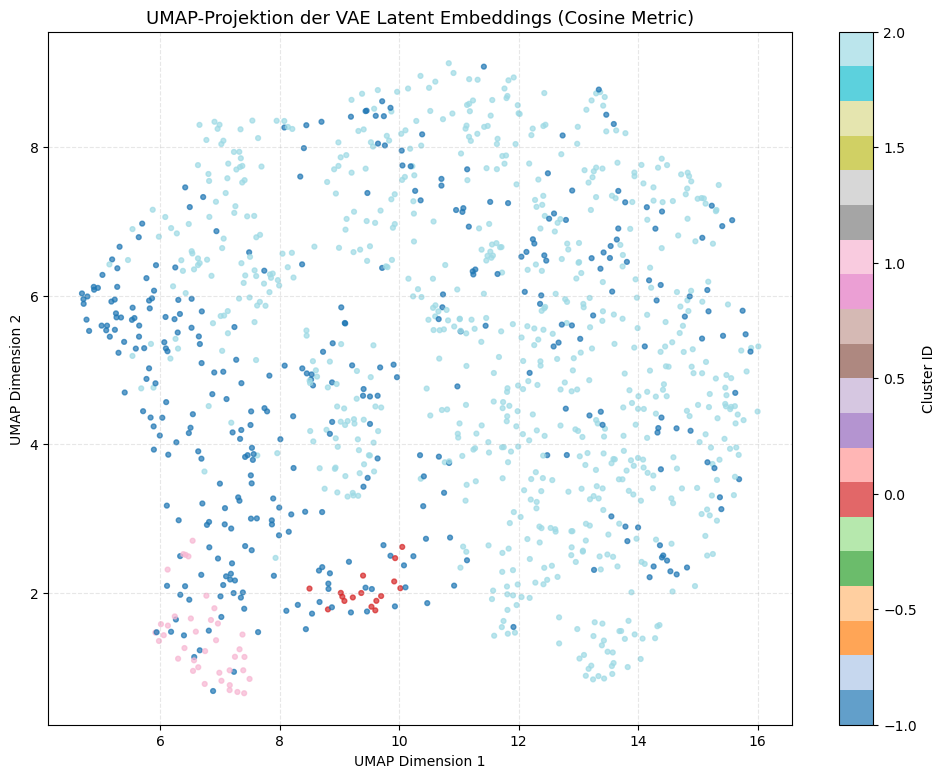

: 

: 

In [ ]:
import umap
import matplotlib.pyplot as plt

reducer = umap.UMAP(
    n_neighbors=20,      # Balance zwischen lokaler und globaler Struktur
    min_dist=0.4,        # Höherer Wert drückt die Punkte weiter auseinander
    metric='cosine',     # Weit weniger anfällig für den Fluch der Dimensionalität
    random_state=42
)

embedding_2d = reducer.fit_transform(embeddings_test)

plt.figure(figsize=(12, 9))
scatter = plt.scatter(
    embedding_2d[:, 0], 
    embedding_2d[:, 1], 
    c=test_df['cluster'], 
    cmap='tab20', 
    s=12,                # Etwas größere Punkte für bessere Lesbarkeit
    alpha=0.7
)

plt.colorbar(scatter, label='Cluster ID')
plt.title('UMAP-Projektion der VAE Latent Embeddings (Cosine Metric)', fontsize=13)
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.grid(True, linestyle='--', alpha=0.3)  # Raster hilft bei der Orientierung
plt.show()